**Adapted from Prof Partha pratim Das at Amity University** 

# Air Quality Across 7 Indian Cities (2023–2025)

**Dataset:** [India AQI Dataset 2023–2025 (Kaggle)](https://www.kaggle.com/datasets/saikiranudayana/india-air-quality-index-aqi-dataset-20232025) — daily CPCB AQI bulletins.
Columns: `date`, `state`, `area`, `number_of_monitoring_stations`, `prominent_pollutants`, `aqi_value`, `air_quality_status`.

### Questions solved in class
1. Which cities have the worst air, and how often is it unhealthy?
2. What does a typical year of air quality "feel like" in each city?
3. Which pollutant is behind the bad air in each city?

### Assignment questions (at the end)
A1. Is there a seasonal pattern, and is it the same everywhere?
A2. Is air quality getting better or worse?
A3. Do cities' pollution levels move together?

In [ ]:
# Run once if a library is missing, then restart the kernel

# %pip install kagglehub
# %pip install matplotlib
# %pip install plotly
# %pip install --upgrade nbformat

## Step 1 — Load the data

In [1]:
import pandas as pd                 # tables and analysis
import matplotlib.pyplot as plt     # charts
import kagglehub, shutil, glob, os

In [2]:
path = kagglehub.dataset_download("saikiranudayana/india-air-quality-index-aqi-dataset-20232025")

csv_file = glob.glob(os.path.join(path, "*.csv"))[0]
DATA_PATH = shutil.copy(csv_file, "./")
print("Saved to:", DATA_PATH)

100%|██████████| 2.03M/2.03M [00:01<00:00, 1.35MB/s]

Extracting files...
Saved to: ./aqi.csv


In [4]:
DATA_PATH = './aqi.csv'          # <- change to the path where downloaded Kaggle file
df_raw = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df_raw.shape)
print("Columns:", list(df_raw.columns))
df_raw.head()

Shape (rows, columns): (235785, 9)
Columns: ['date', 'state', 'area', 'number_of_monitoring_stations', 'prominent_pollutants', 'aqi_value', 'air_quality_status', 'unit', 'note']


,date,state,area,number_of_monitoring_stations,prominent_pollutants,aqi_value,air_quality_status,unit,note
0,30-04-2025,Maharashtra,Amravati,2,PM10,78,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
1,30-04-2025,Bihar,Purnia,1,CO,56,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
2,30-04-2025,Madhya Pradesh,Katni,1,O3,98,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
3,30-04-2025,Chhattisgarh,Tumidih,1,PM10,103,Moderate,number_of_monitoring_stations in Absolute Numb...,NaN
4,30-04-2025,Assam,Byrnihat,1,PM2.5,61,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN


## Step 2 — Clean the data

In [5]:
# Remove columns we don't need ('unit' is constant, 'note' is empty)
df = df_raw.drop(columns=['unit', 'note'], errors='ignore')
print("Columns before:", list(df_raw.columns))
print("Columns after: ", list(df.columns))

Columns before: ['date', 'state', 'area', 'number_of_monitoring_stations', 'prominent_pollutants', 'aqi_value', 'air_quality_status', 'unit', 'note']
Columns after:  ['date', 'state', 'area', 'number_of_monitoring_stations', 'prominent_pollutants', 'aqi_value', 'air_quality_status']


In [6]:
# Convert the 'date' column from text into real dates (dataset uses DD-MM-YYYY)
print("Before:", df['date'].dtype, "| example:", df['date'].iloc[0])
df['date'] = pd.to_datetime(df['date'], dayfirst=True, format='mixed')
print("After: ", df['date'].dtype, "| example:", df['date'].iloc[0])

Before: object | example: 30-04-2025
After:  datetime64[ns] | example: 2025-04-30 00:00:00


In [7]:
# Cities we will compare, and the region each belongs to
cities = ['Delhi', 'Lucknow', 'Amritsar', 'Mumbai', 'Hyderabad', 'Bengaluru', 'Chennai']
region = {'Delhi': 'North', 'Lucknow': 'North', 'Amritsar': 'North', 'Mumbai': 'West',
          'Hyderabad': 'South', 'Bengaluru': 'South', 'Chennai': 'South'}

df['area'] = df['area'].str.strip()         # remove stray spaces so names match exactly
before = len(df)
df = df[df['area'].isin(cities)]            # keep only rows for our cities
print(f"Rows before: {before}  |  after: {len(df)}")
print("Cities:", sorted(df['area'].unique()))
print("Cities NOT found (check spelling):", set(cities) - set(df['area']))

Rows before: 235785  |  after: 7788
Cities: ['Amritsar', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Lucknow', 'Mumbai']
Cities NOT found (check spelling): set()


In [8]:
# Keep one reading per city per day, sorted by city then date
before = len(df)
df = df.drop_duplicates(subset=['date', 'area']).sort_values(['area', 'date'])
print("Duplicate rows removed:", before - len(df))

# Add helper columns for grouping later
df['region'] = df['area'].map(region)       # North / West / South
df['year'] = df['date'].dt.year             # e.g. 2024
df['month'] = df['date'].dt.month           # 1 to 12
print(df[['date', 'area', 'region', 'year', 'month']].head())

Duplicate rows removed: 0
             date      area region  year  month
235745 2022-04-01  Amritsar  North  2022      4
235568 2022-04-02  Amritsar  North  2022      4
235367 2022-04-03  Amritsar  North  2022      4
235288 2022-04-04  Amritsar  North  2022      4
235173 2022-04-05  Amritsar  North  2022      4


In [9]:
# Data quality: empty cells, and how many days each city actually reports
print("Missing values per column:\n", df.isna().sum(), "\n")

coverage = df.groupby('area')['date'].agg(first='min', last='max', days='count')
coverage['coverage_%'] = (100 * coverage['days'] / ((coverage['last'] - coverage['first']).dt.days + 1)).round(1)
print(coverage.sort_values('coverage_%'))

Missing values per column:
 date                             0
state                            0
area                             0
number_of_monitoring_stations    0
prominent_pollutants             0
aqi_value                        0
air_quality_status               0
region                           0
year                             0
month                            0
dtype: int64 

               first       last  days  coverage_%
area                                             
Amritsar  2022-04-01 2025-04-24  1041        92.9
Chennai   2022-04-01 2025-04-30  1123        99.7
Mumbai    2022-04-01 2025-04-30  1124        99.8
Bengaluru 2022-04-01 2025-04-30  1125        99.9
Delhi     2022-04-01 2025-04-30  1125        99.9
Hyderabad 2022-04-01 2025-04-30  1125        99.9
Lucknow   2022-04-01 2025-04-30  1125        99.9


## Q1 — Which cities have the worst air, and how often is it unhealthy?
AQI above 200 = **Poor or worse** (Poor, Very Poor, Severe).

In [10]:
q1 = df.groupby('area')['aqi_value'].agg(['mean', 'median', 'max'])            # AQI summary per city
q1['poor_days_%'] = (df['aqi_value'] > 200).groupby(df['area']).mean() * 100    # share of days with AQI > 200
q1 = q1.sort_values('mean', ascending=False)                                     # worst city first
print(q1.round(1))

            mean  median  max  poor_days_%
area                                      
Delhi      206.4   194.0  494         46.9
Lucknow    131.1   123.0  311         15.6
Amritsar   121.9   106.0  368         10.3
Mumbai     105.9    92.0  281          5.4
Hyderabad   81.0    82.0  171          0.0
Bengaluru   74.9    72.0  172          0.0
Chennai     74.0    68.0  245          0.6


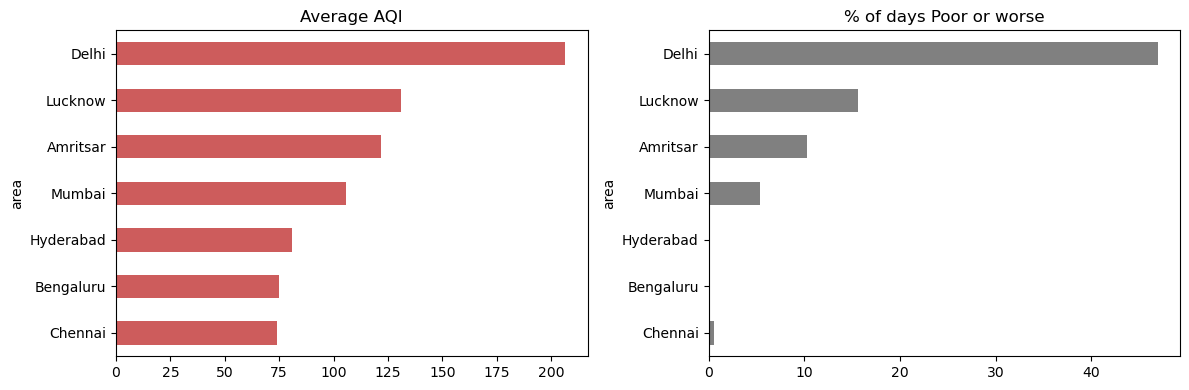

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
q1['mean'].plot.barh(ax=ax[0], color='indianred', title='Average AQI').invert_yaxis()
q1['poor_days_%'].plot.barh(ax=ax[1], color='gray', title='% of days Poor or worse').invert_yaxis()
plt.tight_layout(); plt.show()

## Q2 — What does a typical year of air quality feel like in each city?

In [12]:
order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
colors = ['#2e7d32', '#9ccc65', '#fdd835', '#fb8c00', '#e53935', '#6a1b9a']
print("Categories in the data:", list(df['air_quality_status'].unique()))   # must match 'order' spelling

q2 = pd.crosstab(df['area'], df['air_quality_status'], normalize='index') * 100   # % of days in each category
q2 = q2.reindex(columns=order, fill_value=0).loc[q1.index]                         # Good→Severe order, Q1 city order
print(q2.round(1))

Categories in the data: ['Moderate', 'Satisfactory', 'Poor', 'Good', 'Very Poor', 'Severe']
air_quality_status  Good  Satisfactory  Moderate  Poor  Very Poor  Severe
area                                                                     
Delhi                0.4          16.9      35.8  25.6       18.0     3.4
Lucknow              8.1          29.3      46.9  15.3        0.4     0.0
Amritsar             1.6          43.0      45.1   9.4        0.9     0.0
Mumbai               9.6          44.9      40.0   5.4        0.0     0.0
Hyderabad            7.3          73.0      19.7   0.0        0.0     0.0
Bengaluru           15.0          72.3      12.7   0.0        0.0     0.0
Chennai             14.2          72.6      12.6   0.6        0.0     0.0


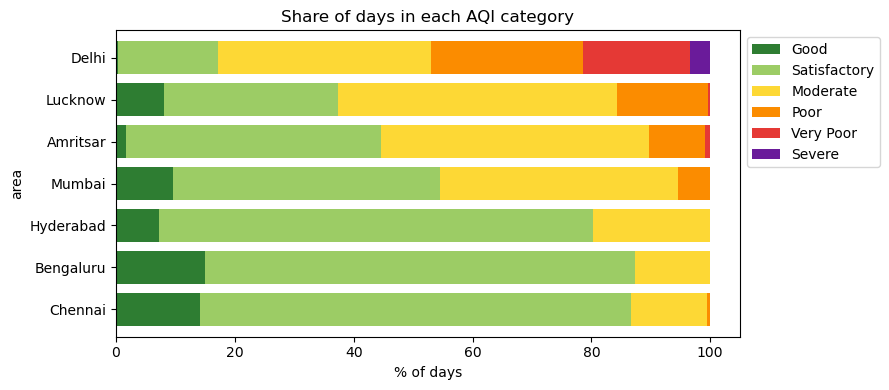

In [13]:
q2.plot.barh(stacked=True, color=colors, figsize=(9, 4), width=0.8,
             title='Share of days in each AQI category').invert_yaxis()
plt.xlabel('% of days'); plt.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

## Q3 — Which pollutant is behind the bad air in each city?
Some days list two pollutants (e.g. `PM2.5,PM10`), so we split them and count each one.

In [14]:
pol = df.assign(pollutant=df['prominent_pollutants'].str.split(',')).explode('pollutant')   # one row per pollutant
pol = pol.reset_index(drop=True).dropna(subset=['pollutant'])                               # fresh index, drop blanks
pol['pollutant'] = pol['pollutant'].str.strip()                                             # tidy spaces
print(f"Rows before split: {len(df)}  |  after: {len(pol)}")
print(pol['pollutant'].value_counts())

Rows before split: 7788  |  after: 13298
pollutant
PM10     5368
PM2.5    4349
CO       1641
O3       1190
NO2       651
SO2        89
SO3         8
NH3         2
Name: count, dtype: int64


In [15]:
q3 = pd.crosstab(pol['area'], pol['pollutant'], normalize='index').mul(100).loc[q1.index]   # % per city
q3 = q3[q3.sum().sort_values(ascending=False).index]                                        # most common first
print(q3.round(1))


pollutant  PM10  PM2.5    CO    O3  NO2  SO2  SO3  NH3
area                                                  
Delhi      37.1   41.2   5.4  12.8  3.5  0.0  0.0  0.0
Lucknow    36.7   46.0   7.8   6.3  3.0  0.2  0.1  0.0
Amritsar   37.6   49.4   3.7   6.7  2.6  0.0  0.0  0.0
Mumbai     37.6   27.0  11.8  11.1  9.8  2.5  0.3  0.0
Hyderabad  49.3   29.0   8.4   7.5  5.9  0.0  0.0  0.0
Bengaluru  49.8   23.6  16.2   7.5  2.6  0.2  0.0  0.0
Chennai    33.3   24.1  26.8   9.5  5.1  1.1  0.0  0.1


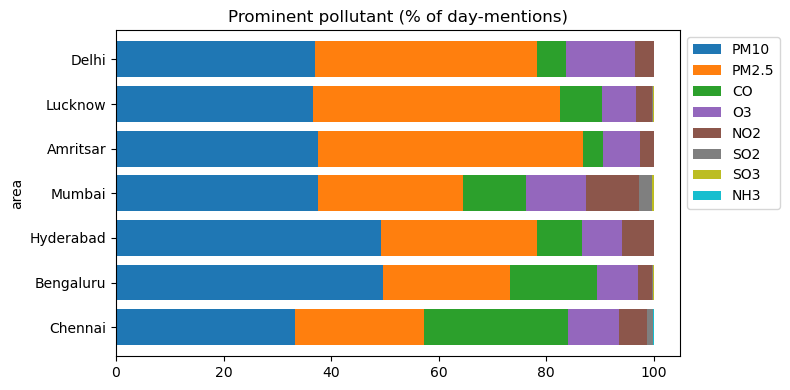

In [16]:
q3.plot.barh(stacked=True, figsize=(8, 4), width=0.8, colormap='tab10',
             title='Prominent pollutant (% of day-mentions)').invert_yaxis()
plt.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

---
# Assignment
Answer each question with code or a chart, and 2–3 sentences explaining what you found.

### Q1 — Is there a seasonal pattern, and is it the same everywhere?
*Hint:* `df.pivot_table(index='area', columns='month', values='aqi_value')`, then compare the worst and best month per city and per `region`.

### A2 — Is air quality getting better or worse?
*Hint:* the data ends in April 2025, so compare **only the same months** across years (e.g. Jan–Apr), grouped by `area` and `year`.

### A3 — Do cities' pollution levels move together?
*Hint:* `df.pivot_table(index='date', columns='area', values='aqi_value').corr()` — use correlation, not covariance.